[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_hhi_coins/BA_L1_hhi_coins.ipynb)

# BA_L1_hhi_coins: Concentration Through Time

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Monthly market-value shares of eleven coins and the Herfindahl-Hirschman index (HHI) with its effective number of coins, November 2014 to October 2025, from the ETH Chronicles on-chain data with the 11 days of recording error removed.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

Monthly means of the daily market value $M_i$ of the eleven coins in the on-chain files; the 11 days of recording
error in Bitcoin's series are removed. The share of coin $i$ is $w_i = M_i / \sum_j M_j$ and the
**Herfindahl–Hirschman index** is

$$\mathrm{HHI} = \sum_{i=1}^{N} w_i^2,$$

from $1/N$ (equal shares) to 1 (one coin). $1/\mathrm{HHI}$ is the **effective number** of coins, the number of
equal-sized coins with the same HHI. The index describes these eleven coins, not the whole market.

**How to read the chart.** Left: stacked shares of Bitcoin, Ethereum, XRP, Dogecoin and the seven other coins.
Right: the HHI (left scale) and the effective number (right scale), which move in opposite directions.

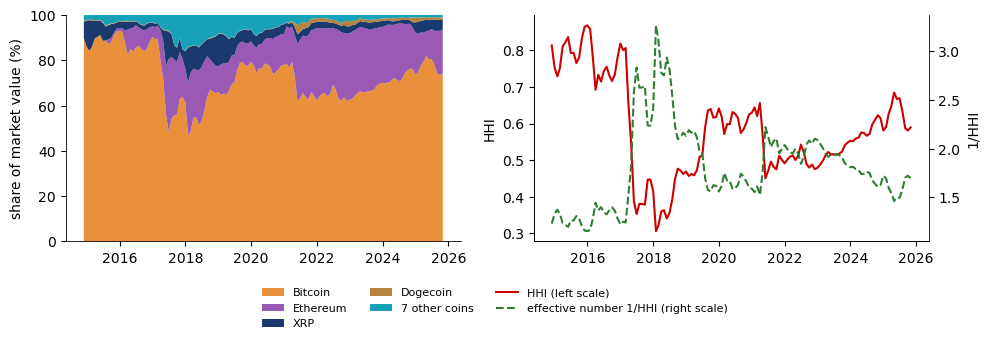

In [5]:
mc = load_onchain('Mktcap')
mc.loc['2023-08-27':'2023-09-06', 'BTC'] = np.nan          # recording error
mm = mc.resample('ME').mean()
wts = mm.div(mm.sum(axis=1, min_count=1), axis=0)
hhi_c = (wts ** 2).sum(axis=1, min_count=1)
top = ['BTC', 'ETH', 'XRP', 'DOGE']

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].stackplot(wts.index, [wts[c].fillna(0) * 100 for c in top] + [wts.drop(columns=top).sum(axis=1) * 100],
                colors=[BTC, ETH, BLUE, GOLD, TEAL], labels=['Bitcoin', 'Ethereum', 'XRP', 'Dogecoin', '7 other coins'])
ax[0].set_ylabel('share of market value (%)'); ax[0].set_ylim(0, 100)
ax[1].plot(hhi_c.index, hhi_c, color=RED, label='HHI (left scale)')
ax2 = ax[1].twinx(); ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(True)
ax2.plot(hhi_c.index, 1 / hhi_c, color=GREEN, ls='--', label='effective number 1/HHI (right scale)')
ax[1].set_ylabel('HHI'); ax2.set_ylabel('1/HHI')
slide_legend(fig, 0.16)
save_fig(fig, 'ba_l1_hhi_coins')

In [6]:
hhi_c = hhi_c.dropna()
rows = [{'month': d, 'HHI': hhi_c.loc[d].iloc[0], 'effective number': 1 / hhi_c.loc[d].iloc[0],
         'Bitcoin share (%)': 100 * wts.loc[d, 'BTC'].iloc[0]}
        for d in [f'{hhi_c.idxmax():%Y-%m}', f'{hhi_c.idxmin():%Y-%m}', '2025-09']]
print(pd.DataFrame(rows).set_index('month').round(3).to_string())
print(f'\nHHI maximum {hhi_c.max():.3f} ({hhi_c.idxmax():%B %Y}); minimum {hhi_c.min():.3f} ({hhi_c.idxmin():%B %Y})')

           HHI  effective number  Bitcoin share (%)
month                                              
2015-12  0.868             1.152             93.085
2018-01  0.306             3.267             47.128
2025-09  0.581             1.722             73.498

HHI maximum 0.868 (December 2015); minimum 0.306 (January 2018)
